In [1]:
import os
import scipy.stats as stats
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.api as sm
import matplotlib.ticker as ticker
import matplotlib.dates as mpldates
import seaborn as sns
from matplotlib.colors import ListedColormap
from Regression_utils import *


In [2]:
main_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Derived All Data.xlsx")
print(main_df.columns)


Index(['Name', 'Year-Month', 'Hours', 'Water Total', 'PSI', 'Revenue',
       'Metered DM', 'Power Factor', 'Billed DM', 'Billing KWH', 'Fuel Rate',
       'Electrical Bill', 'Workover Info', 'Workover Cost', 'Pump Model',
       'Pump Number', 'Plunger Size', 'Install Date', 'Maintenance Cost',
       'Maintenance Comments', 'KWH per Barrel', 'Cost per KWH',
       'Electrical Cost per Barrel', 'Maintenance Cost per Barrel',
       'Workover Cost per Barrel', 'Revenue per Barrel', 'Income per Barrel',
       'Income', 'Total Cost', '6 Month Avg Water Total', '6 Month Avg KWH',
       '6 Month Avg Revenue', '6 Month Avg Income', '6 Month Avg Total Cost',
       '6 Month Avg KWH per Barrel Weighted', '6 Month Avg Cost per KWH',
       '6 Month Avg Electrical Cost per Barrel',
       '6 Month Avg Maintenance Cost per Barrel',
       '6 Month Avg Workover Cost per Barrel',
       '6 Month Avg Revenue per Barrel', '6 Month Avg Income per Barrel',
       'Cumulative Electrical Cost', 'Cumul

Name
ABNEY #2        0
ABNEY #3        1
ALBERTSON #4    1
BASS #4         0
BASS #5         1
               ..
WILLIAMS #6     2
WILLIAMS #7     0
WILLIAMS #8     1
WILLIAMS #9     3
WILSON #4       2
Name: Workover Count, Length: 87, dtype: int64
46
87


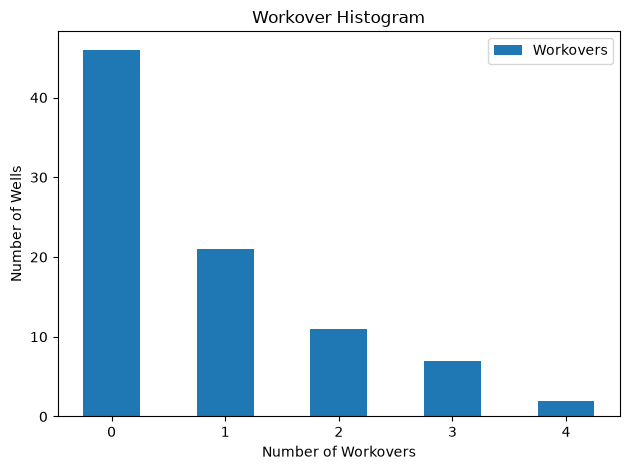

,Name,Year-Month,Hours,Water Total,PSI,Revenue,Metered DM,Power Factor,Billed DM,Billing KWH,...,6 Month Avg Workover Cost,Workover Count,Disposal Rate,Date,Period,Log Billing KWH,Sqrt Electrical Bill,Sqrt Metered DM,First Workover Date,Second Workover Date
0,ABNEY #2,2017-08,883.922017,503920,772.857143,18566.216116,194.4,88.2,198.4,125200.0,...,NaN,0,570.095540,2017-08-01,2017-08,11.737676,77.286739,13.942740,2000-01,2000-01
1,ABNEY #2,2017-09,910.129905,518861,777.142857,20320.151624,194.4,88.2,198.4,129440.0,...,NaN,0,570.095540,2017-09-01,2017-09,11.770980,78.317878,13.942740,2000-01,2000-01
2,ABNEY #2,2017-10,926.036011,527929,782.857143,20470.111597,196.8,88.1,201.0,148320.0,...,NaN,0,570.095540,2017-10-01,2017-10,11.907134,82.851192,14.028542,2000-01,2000-01
3,ABNEY #2,2017-11,884.029017,503981,774.285714,20120.328465,197.6,87.8,202.6,129440.0,...,NaN,0,570.095540,2017-11-01,2017-11,11.770980,78.637841,14.057027,2000-01,2000-01
4,ABNEY #2,2017-12,834.928475,475989,773.333333,19138.079039,192.0,87.6,197.3,127120.0,...,NaN,0,570.095540,2017-12-01,2017-12,11.752895,77.863278,13.856406,2000-01,2000-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8521,WILSON #4,2025-05,748.000000,218425,754.440000,14196.677810,81.9,99.7,81.9,53040.0,...,0.0,0,292.012032,2025-05-01,2025-05,10.878820,59.159361,9.049862,2000-01,2000-01
8522,WILSON #4,2025-06,713.820000,213333,772.220000,13964.023259,82.3,99.3,82.3,56400.0,...,0.0,0,298.861057,2025-06-01,2025-06,10.940242,60.589933,9.071935,2000-01,2000-01
8523,WILSON #4,2025-07,139.210000,41763,810.000000,2731.968980,85.7,98.9,85.7,40560.0,...,0.0,0,300.000000,2025-07-01,2025-07,10.610562,54.143328,9.257429,2000-01,2000-01
8524,WILSON #4,2025-08,0.000000,0,0.000000,0.000000,0.1,44.7,0.1,80.0,...,0.0,0,0.000000,2025-08-01,2025-08,4.394449,30.542757,0.316228,2000-01,2000-01


In [83]:
main_df["Workover Count"] = np.where(
    main_df["Workover Cost"] > 1, 
    1, 
    0
)

main_df["Disposal Rate"] = np.where(
    main_df["Hours"] > 0,
    main_df["Water Total"] / main_df["Hours"],
    0
)
# matplotlib doesn't like the pure string values for Year-Month
main_df["Date"] = pd.to_datetime(main_df["Year-Month"])
main_df["Period"] = pd.to_datetime(main_df["Year-Month"]).dt.to_period(freq="M")
#print(main_df["Period"])

#main_df["Year-Month"] = main_df["Year-Month"].dt.to_period("M")

# Get a count of workovers for each well
print(main_df.groupby("Name")["Workover Count"].sum())
workover_counts = main_df.groupby("Name")["Workover Count"].sum()
no_workover = workover_counts[(workover_counts < 1)]
print(len(no_workover))
print(len(workover_counts))
fig, ax = plt.subplots()

max_val = int(max(workover_counts))
bins = range(0, max_val + 2)
ax.hist(workover_counts, bins=bins, align="left", rwidth = 0.5)

ax.set_title("Workover Histogram")
ax.legend(["Workovers"])
ax.set_xlabel("Number of Workovers")
ax.set_ylabel("Number of Wells")
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.xaxis.set_major_locator(ticker.MultipleLocator(1.0))
plt.tight_layout()
plt.show()


#example global variable
TOTAL_WORKOVER_COST = main_df["Workover Cost"].sum()

main_df.dropna(subset = ["Billing KWH", "Electrical Bill", "Metered DM"])


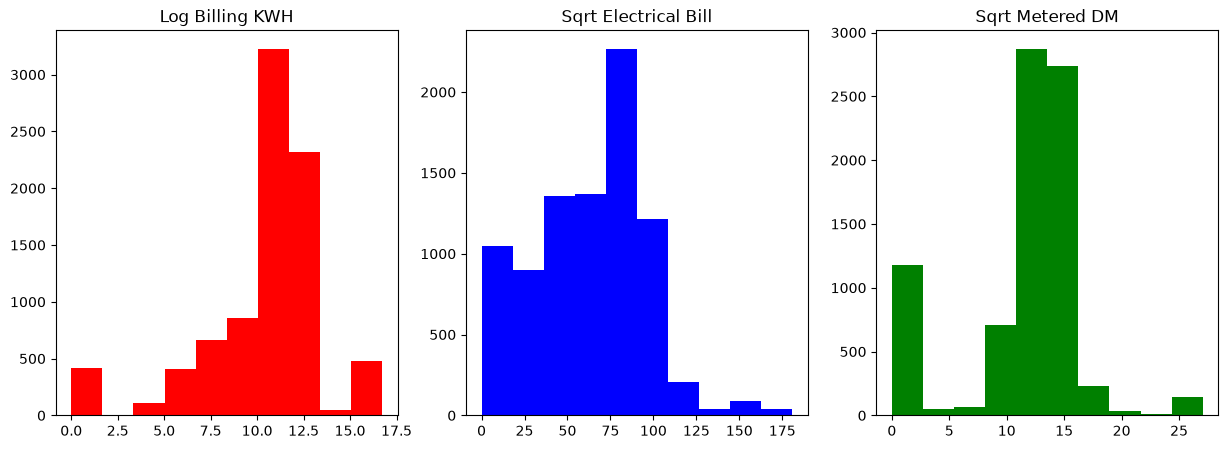

In [4]:
#Getting an approximately normal data distribution
main_df["Log Billing KWH"] = np.log1p(main_df["Billing KWH"])
main_df["Sqrt Electrical Bill"] = np.sqrt(main_df["Electrical Bill"])
main_df["Sqrt Metered DM"] = np.sqrt(main_df["Metered DM"])

fig, axs = plt.subplots(1, 3, figsize = (15, 5))

axs[0].hist(main_df["Log Billing KWH"], color="red")
axs[0].set_title("Log Billing KWH")

axs[1].hist(main_df["Sqrt Electrical Bill"], color="blue")
axs[1].set_title("Sqrt Electrical Bill")

axs[2].hist(main_df["Sqrt Metered DM"], color="green")
axs[2].set_title("Sqrt Metered DM")

plt.show()


NameError: name 'column' is not defined

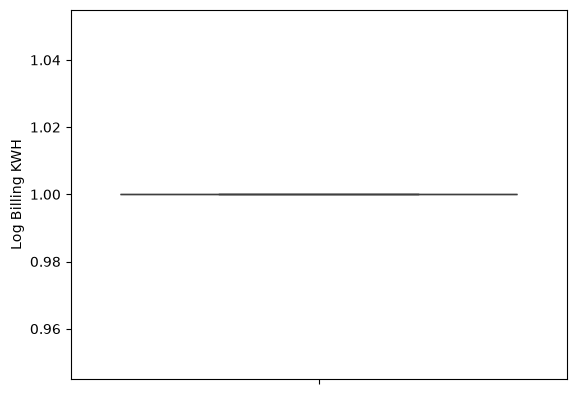

In [172]:
"""remove outliers"""
sqrt_dm_filtered = main_df.loc[main_df["Sqrt Metered DM"] > 0, "Sqrt Metered DM"]
sqrt_bill_filtered = main_df.loc[main_df["Sqrt Electrical Bill"] > 0, "Sqrt Electrical Bill"]
log_kwh_filtered = main_df.loc[main_df["Log Billing KWH"] > 0, "Log Billing KWH"]

sqrt_dm_filtered

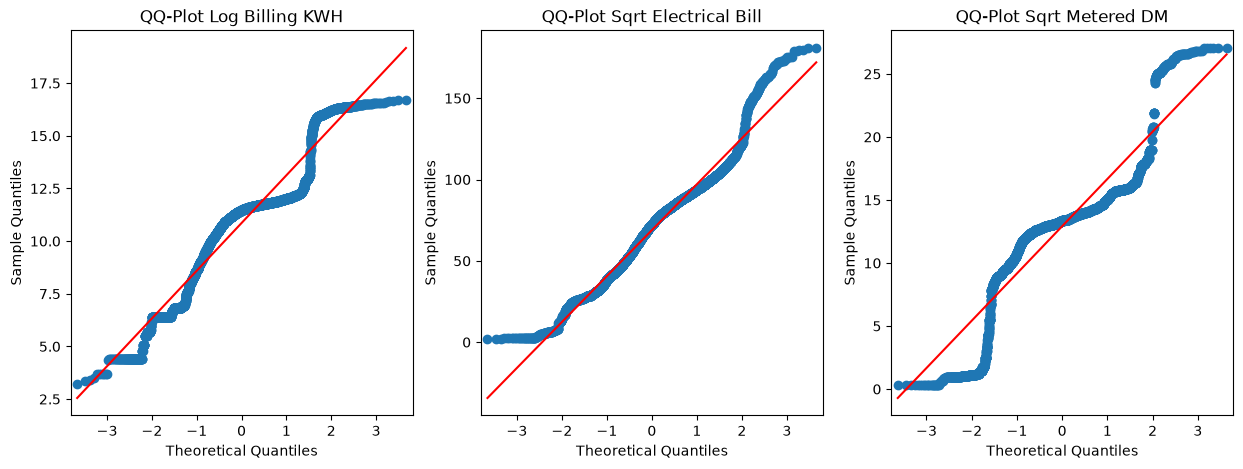

In [5]:
# QQ-plots
fig, axs = plt.subplots(1, 3, figsize = (15, 5))

sm.qqplot(log_kwh_filtered, line = "s", ax=axs[0])
axs[0].set_title("QQ-Plot Log Billing KWH")

sm.qqplot(sqrt_bill_filtered, line = "s", ax=axs[1])
axs[1].set_title("QQ-Plot Sqrt Electrical Bill")

sm.qqplot(sqrt_dm_filtered, line = "s", ax=axs[2])
axs[2].set_title("QQ-Plot Sqrt Metered DM")

plt.tight_layout
plt.show()


In [85]:
#Date Processing
# Filtering the data to between pre and post workover.
#KWH_filt = KWH_df.drop((KWH_df["Workover Count"] > 0) & (KWH_df["Workover Count"] <2))
#KWH_filt.tail()
main_df["First Workover Date"] = pd.to_datetime("2000-01", format = "%Y-%m")
main_df["First Workover Date"] = main_df["First Workover Date"].dt.to_period("M")
main_df["Second Workover Date"] = pd.to_datetime("2000-01", format = "%Y-%m")
main_df["Second Workover Date"] = main_df["Second Workover Date"].dt.to_period("M")

wells = main_df["Name"].unique()
#print(wells)
#Assigning workover dates to each well
for well in wells:
    well_filt = main_df["Name"] == well
    work_filt = main_df["Workover Count"] == 1
    full_filt = (well_filt) & (work_filt)
    
    # filter example -> main_df[full_filt]["Year-Month"]
    if len(main_df[full_filt]) == 1:
        main_df.loc[full_filt, "First Workover Date"] = main_df[full_filt]["Year-Month"]
        print(well, " 1")
        print(main_df[full_filt]["First Workover Date"])
        
    elif len(main_df[full_filt]) > 1:
        # first date = first workover date
        # second date = second workover date
        first_date = main_df.loc[full_filt, "Year-Month"].iloc[0]
        second_date = main_df.loc[full_filt, "Year-Month"].iloc[1]

        main_df.loc[full_filt, "First Workover Date"] = first_date
        main_df.loc[full_filt, "Second Workover Date"] = second_date
        
        print(well, "> 1")
        print(main_df[full_filt]["First Workover Date"])
        print(main_df.loc[full_filt, "Second Workover Date"])

ABNEY #3  1
193    2025-07
Name: First Workover Date, dtype: period[M]
ALBERTSON #4  1
255    2022-07
Name: First Workover Date, dtype: period[M]
BASS #5  1
417    2019-09
Name: First Workover Date, dtype: period[M]
BLUM #7  1
1254    2024-02
Name: First Workover Date, dtype: period[M]
BOLDRICK #1 > 1
1372    2017-08
1400    2017-08
Name: First Workover Date, dtype: period[M]
1372    2019-12
1400    2019-12
Name: Second Workover Date, dtype: period[M]
BOLDRICK #2 > 1
1486    2018-12
1518    2018-12
Name: First Workover Date, dtype: period[M]
1486    2021-08
1518    2021-08
Name: Second Workover Date, dtype: period[M]
BOLES #1  1
1764    2017-08
Name: First Workover Date, dtype: period[M]
COLVILLE #4  1
2214    2022-06
Name: First Workover Date, dtype: period[M]
COLVILLE #5 > 1
2312    2022-06
2320    2022-06
Name: First Workover Date, dtype: period[M]
2312    2023-02
2320    2023-02
Name: Second Workover Date, dtype: period[M]
CUNYUS #4 > 1
2685    2020-11
2706    2020-11
2712    2020-

In [86]:
#Paired t-test for the wells with 1 workover
# attrs is a list of column names
# TODO: implement (ttest_workovers(attrs: list[str], month_count, workover_number))
def ttest_workovers(attrs: list[str], in_df, month_count:int = 6, workover_number:int = 1) -> pd.DataFrame:
    """ Conducts a t-test on both each individual well and all wells for the provided attributes. 
    Attrs is a list of column names from the dataframe of interest. Month count is the number of months 
    to be used in selecting rows before and after a workover. Workover number indicates which (first, second)
    workover we are looking for. 

    returns pd.DataFrame
    """
    rows = []
    
    
    # adjust workover number to allow for indexing to start at 1 for easier interpretation
    workover_pos = workover_number - 1

    # dataframes designed to show values 6 months before and after workovers for all wells
    total_before_df = pd.DataFrame()
    total_after_df = pd.DataFrame()

    
    # Paired T-test for first workover date
    for well in wells:
        # Filter to this well
        well_filt = in_df["Name"] == well
    
        # ascending sort oldest to newest records
        well_df = in_df[well_filt].sort_values("Year-Month").reset_index(drop=True)
    
        # Find the row(s) where Year-Month matches the workover date
        workover_rows = well_df[well_df["Workover Count"] == 1]
    
        if workover_rows.empty:
            # No matching workover date found for this well — skip
            continue

        try:
            # Get the integer position of the workover month
            workover_idx = workover_rows.index[0]
            workover_idx = workover_rows.index[workover_pos]
            
            # Slice month_count months before (not including workover month)
            if (workover_idx - month_count) >= 0:
                before_df = well_df.iloc[(workover_idx - month_count):workover_idx]
            else:
                print(f"Not enough months before workover available for {well}")
                continue
        
            # Slice month_count months after (not including workover month)
            if (workover_idx + month_count) < len(well_df):
                after_df = well_df.iloc[workover_idx + 1: workover_idx + month_count + 1]
            else:
                print(f"Not enough months after workover available for {well}")
                continue
                
               # Only keep this well if it has enough months on both sides
            if len(before_df) == month_count and len(after_df) == month_count:
                # concatenate the months before and after workover for each well into a single dataframe
                total_before_df = pd.concat([total_before_df, before_df])
                total_after_df = pd.concat([total_after_df, after_df])
                
                for attr in attrs:
                    before = before_df[attr].to_numpy()
                    after = after_df[attr].to_numpy()
                    
                    #if length of n is less than 2, the T-test will throw and error
                    if len(before) < 2:
                        t_stat, p_value = np.nan, np.nan
                    else: 
                        result = stats.ttest_rel(before, after)
                        t_stat, p_value = result.statistic, result.pvalue
                        
                    #columns for the dataframe
                    rows.append({
                        "Well": well,
                        "Attribute": attr,
                        "Months": month_count,
                        "Workover": workover_number,
                        "N_pairs": len(before),
                        "T_stat": t_stat, 
                        "P_value": p_value
                    })

                  
        except IndexError as exc:
            print("Index not valid for well", well, exc)
            
    for attr in attrs:
        total_before = total_before_df[attr].to_numpy()
        total_after = total_after_df[attr].to_numpy()

        #if length of n is less than 2, the T-test will throw and error
        if len(total_before) < 2:
            t_stat, p_value = np.nan, np.nan
        else:
            #Nan policy is omitted in the tests across multiple wells due to large sample of pairs
            result = stats.ttest_rel(total_before, total_after, nan_policy="omit")
            t_stat, p_value = result.statistic, result.pvalue
            
        #columns for the dataframe    
        rows.append({"Well": "All wells", 
                     "Attribute": attr, 
                     "Months": month_count, 
                     "Workover": workover_number,
                     "N_pairs": len(total_before),
                     "T_stat": t_stat, 
                     "P_value": p_value
                    })
        
    return pd.DataFrame(rows)


In [87]:
attributes = ["Billing KWH", "Log Billing KWH", "Electrical Bill", "Sqrt Electrical Bill", "Metered DM", "Sqrt Metered DM"]
month_counts = [3, 6, 12]
workover_counts = [1, 2]

results = []
for month in month_counts:
    print(f"Testing {month} months")
    for workover in workover_counts:
        print(f"Testing {workover} workovers")
        results.append(ttest_workovers(attributes, main_df, month, workover))

ttest_df = pd.concat(results, ignore_index=True)
#rounding p-values to 4 decimal places
ttest_df["P_value"] = ttest_df["P_value"].round(4) 

Testing 3 months
Testing 1 workovers
Not enough months after workover available for ABNEY #3
Not enough months before workover available for BOLDRICK #1
Not enough months before workover available for BOLES #1
Not enough months before workover available for HUGHES #4
Not enough months before workover available for LAKE #2
Not enough months before workover available for LAKE #4
Not enough months before workover available for LAKE #6
Not enough months before workover available for MOYAR #2
Not enough months before workover available for O'DONNELL #4
Not enough months before workover available for PAYNE #7
Not enough months after workover available for WILLIAMS #1
Not enough months before workover available for WILLIAMS #2
Not enough months before workover available for WILLIAMS #9
Testing 2 workovers
Index not valid for well ABNEY #3 index 1 is out of bounds for axis 0 with size 1
Index not valid for well ALBERTSON #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for we

C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\scipy\stats\_axis_nan_policy.py:431: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  return hypotest_fun_in(*args, **kwds)
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\scipy\stats\_axis_nan_policy.py:431: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  return hypotest_fun_in(*args, **kwds)


Index not valid for well SUMAN #8 index 1 is out of bounds for axis 0 with size 1
Index not valid for well SUNKEL #3 index 1 is out of bounds for axis 0 with size 1
Index not valid for well THOMPSON #3 index 1 is out of bounds for axis 0 with size 1
Index not valid for well WILLIAMS #1 index 1 is out of bounds for axis 0 with size 1
Index not valid for well WILLIAMS #11 index 1 is out of bounds for axis 0 with size 1
Index not valid for well WILLIAMS #8 index 1 is out of bounds for axis 0 with size 1
Testing 6 months
Testing 1 workovers
Not enough months after workover available for ABNEY #3
Not enough months before workover available for BOLDRICK #1
Not enough months before workover available for BOLES #1
Not enough months before workover available for HUGHES #4
Not enough months before workover available for KEE #6
Not enough months before workover available for LAKE #2
Not enough months before workover available for LAKE #4
Not enough months before workover available for LAKE #6
Not

In [88]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(ttest_df)

,Well,Attribute,Months,Workover,N_pairs,T_stat,P_value
0,ALBERTSON #4,Billing KWH,3,1,3,4.182727,0.0527
1,ALBERTSON #4,Log Billing KWH,3,1,3,3.882359,0.0604
2,ALBERTSON #4,Electrical Bill,3,1,3,4.582871,0.0445
3,ALBERTSON #4,Sqrt Electrical Bill,3,1,3,4.429644,0.0474
4,ALBERTSON #4,Metered DM,3,1,3,16.000000,0.0039
5,ALBERTSON #4,Sqrt Metered DM,3,1,3,14.605008,0.0047
6,BASS #5,Billing KWH,3,1,3,1.889165,0.1995
7,BASS #5,Log Billing KWH,3,1,3,1.706908,0.2300
8,BASS #5,Electrical Bill,3,1,3,3.746927,0.0644
9,BASS #5,Sqrt Electrical Bill,3,1,3,3.283754,0.0816


In [132]:
"""Provide the proportion of electrical bill that is significant. Additionally, find out electrical bill and KWH/MDM differ"""
ttest_df.dropna(subset = ["P_value"])
#Binary Column added to df
ttest_df["Significant"] = (ttest_df["P_value"] < 0.05).astype(int)


wells = ttest_df["Well"].unique()

In [140]:
signif_df = ttest_df[["Well", "Attribute", "Significant"]]

insig_filt = signif_df["Significant"] == 0
elec_filt = signif_df["Attribute"]
full_filt = sig_filt & elec_filt
#print(ttest_df[full_filt]["Well"])

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_26956\2437815216.py:5: Pandas4Warning: 'and' operations between boolean dtype and str are deprecated and will raise in a future version. Explicitly cast the strings to a boolean dtype before operating instead.
  full_filt = sig_filt & elec_filt


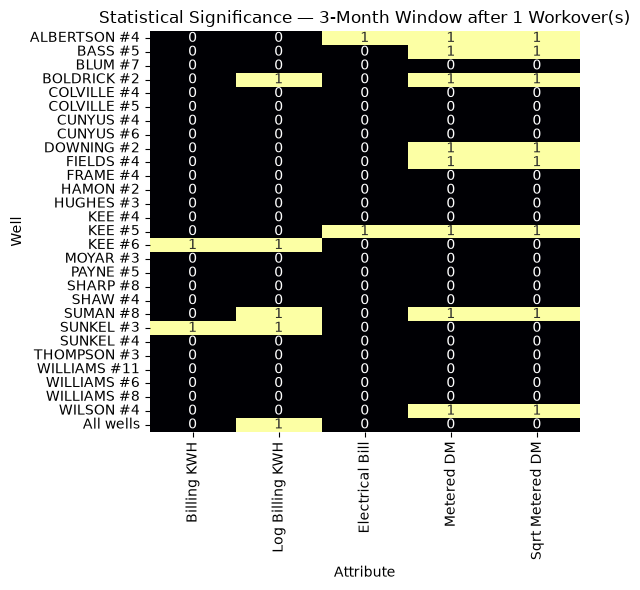

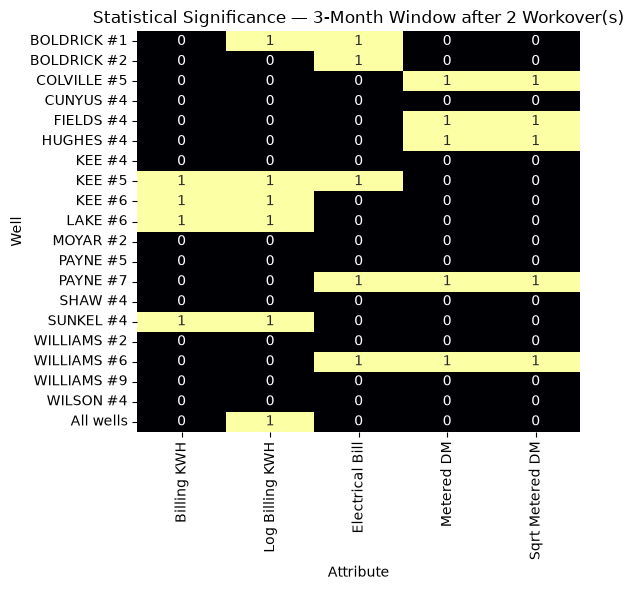

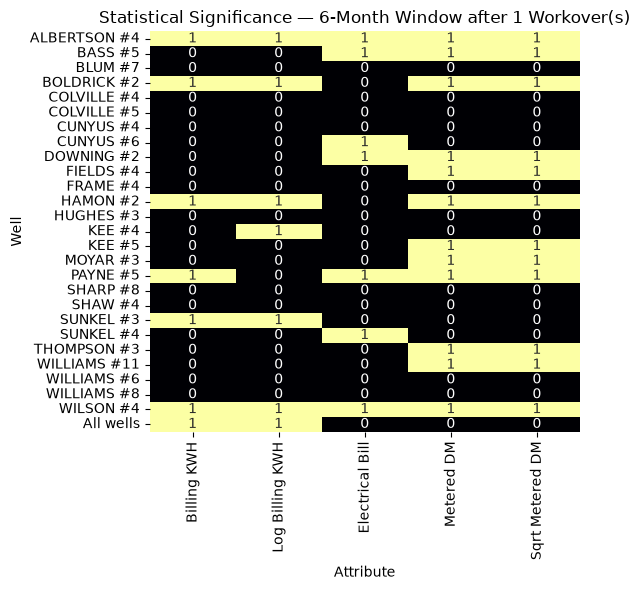

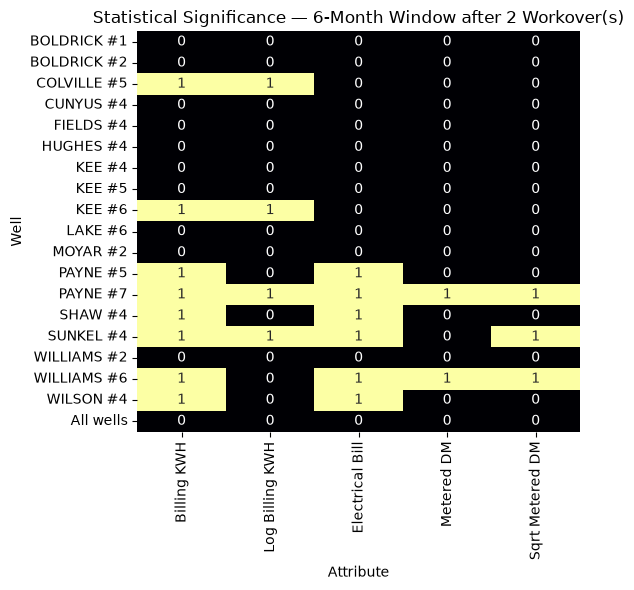

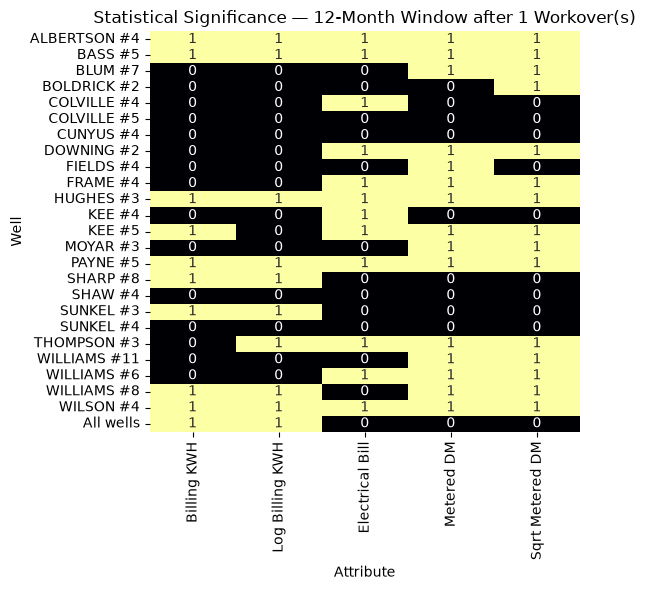

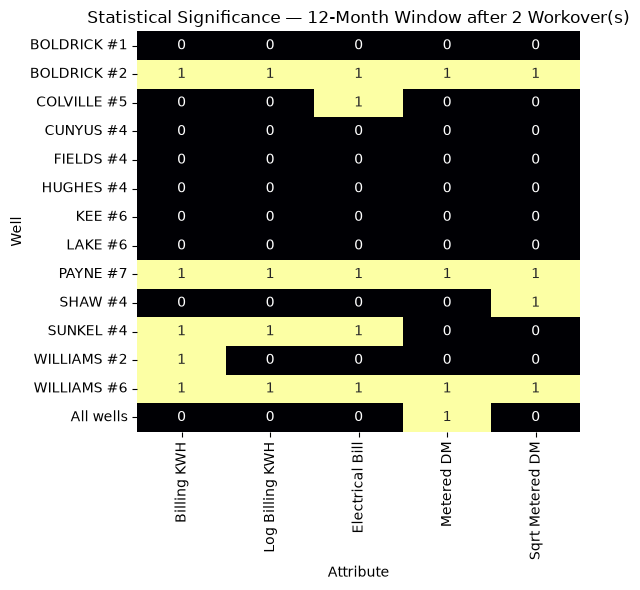

In [134]:
window_test = [3, 6, 12]
workovers_test = [1,2]
for window in window_test:
    for work in workovers_test:
        #creating the dataframe for the binary matrix using the lists above
        window_df = ttest_df[(ttest_df["Months"] == window) & (ttest_df["Workover"] == work)]
        binary_matrix = window_df.pivot(index = "Well", columns = "Attribute", values = "Significant")
        #changing the order of the columns
        binary_matrix = binary_matrix.reindex(columns = attribute_order)
        #changing the order of the index
        well_order = [
            well for well in binary_matrix.index
            if well != "All wells"
        ]
        
        if "All wells" in binary_matrix.index:
            well_order.append("All wells")
        
        binary_matrix = binary_matrix.reindex(well_order)
        
        #plotting the heatmap figure
        plt.figure(figsize=(6, 6))
        sns.heatmap(
            binary_matrix, 
            annot = True,
            cmap = "inferno",
            vmin = 0,
            vmax = 1,
            cbar = False
        )
        
        plt.title(f"Statistical Significance — {window}-Month Window after {work} Workover(s)")
        plt.xlabel("Attribute")
        plt.ylabel("Well")
        plt.tight_layout()
        #plt.show()